### Refined Question and Analysis Choices:

Central question: 
Are there shifts in invasive plant species presence before and after a prescribed burn takes place? 
Supporting questions: Are there changes in the number of invasive species observations before and after a prescribed burn? Are there changes in species richness of invasive species before and after a prescribed burn? Do different treatment types affect different invasive species?

Observations: 
Each observation in our data set is an invasive species plant observation that was observed within the polygon of a prescribed fire. Each row of observation includes basic information about the species observed, as well as information about the prescribed burn that its coordinate is contained within.

Variables: 
The variables we are using to analyze this question are “id” to derive observation counts from, “scientific_name” to derive species richness within a prescribed fire, “start_date” to label when a species is observed before a prescribed fire occurs, “end_date” to label when a species is observed after a prescribed fire occurs, “treatment_type” to observe if there are differences, and “acres_treated” to find the average number of species observations per hectare of prescribed burn. 

Units: 
There are no units for “id,” “scientific_name,” and “treatment_type.” “start_date” and “end_date” are formatted into dates, and also have no units. “acres_treated” has a unit of acres.
Intended comparison: We plan on comparing observation counts and species counts one year before and after the prescribed fire occurred to calculate if there is a change in invasive species presence.

Unresolved data limitations:
Because we are using citizen science for our observation data, our data may be subject to observation bias.
Another unresolved data limitation we have is figuring out what time range we should filter our observations to. The majority of our observations occurred starting 2019, so we aren’t sure if we should just filter out observations prior to 2019 and fires that occurred prior to 2020, or if we should still conduct our analysis spanning all years of our current dataset.

### Plots and Table for Week 3

In [2]:
# Prepare environment
from pathlib import Path
import pandas as pd
import geopandas as gpd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

# Set file paths
root_fldr = Path.cwd().parent
raw_fldr = root_fldr/"data"/"raw"
processed_fldr = root_fldr/'data'/'processed'
fire_with_plants_joined = gpd.read_file(processed_fldr / "fire_with_plants_joined.gpkg")
invasives_within_year = gpd.read_file(processed_fldr / "invasives_within_year.gpkg")

invasives_within_year = gpd.GeoDataFrame(
    invasives_within_year,
    geometry="geometry",
    crs="EPSG:3310"
)

In [3]:
#AI consultation: how to add california outline to map
states = gpd.read_file(
    "https://www2.census.gov/geo/tiger/GENZ2024/shp/cb_2024_us_state_500k.zip"
)
states = states.to_crs(fire_with_plants_joined.crs)
cal_outline = states.loc[states["NAME"] == "California"]

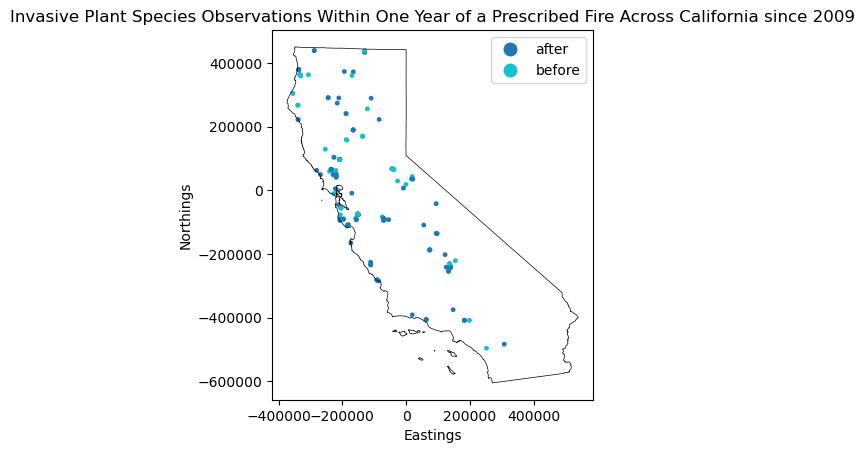

In [4]:
fig, ax = plt.subplots()

cal_outline.boundary.plot(
    ax=ax,
    color="black",
    linewidth=0.5
)

invasives_within_year.plot(
    markersize=6,
    column="before_after",
    legend=True,
    ax=ax
)

plt.title("Invasive Plant Species Observations Within One Year of a Prescribed Fire Across California since 2009");
plt.xlabel("Eastings");
plt.ylabel("Northings");

Figure Overview: 
This figure looks at the question: are there changes in invasive species presence before and after prescribed fires occur? To observe this question, we counted the number of species observations one year before a prescribed burn took place, and observations one year after a prescribed burn. We then plotted these observations spatially for all prescribed burns across California since 2009. There are no units for the points themselves, as they each represent one observation. Our spatial plot is in Northings and Eastings. There isn’t a clear pattern observed from our points. We see that in certain prescribed burn regions, the presence of invasive species disappeared within a year after the fire. However, in other regions, we see that there previously were no invasive species, and they had popped up within a year after the prescribed fire.

Limitation:
One of our biggest limitations is that for most fires, there is only one observation before or after the prescribed fire. This doesn’t give us enough data per fire to make a correlation between the occurrence of a fire and the presence of invasive species. Another limitation we recognize is that multiple prescribed fires could have occurred in the same place or overlap regions. This overlap is not reflected within our figure.

Findings:
We observe that there is a larger presence of observations in general in Northern California compared to Southern California. In Northern California, there are more invasive species that have been observed a year before prescribed burns that have disappeared after that year. Invasive species that have occurred within a year after a prescribed burn are scattered throughout the state with no pattern detected.

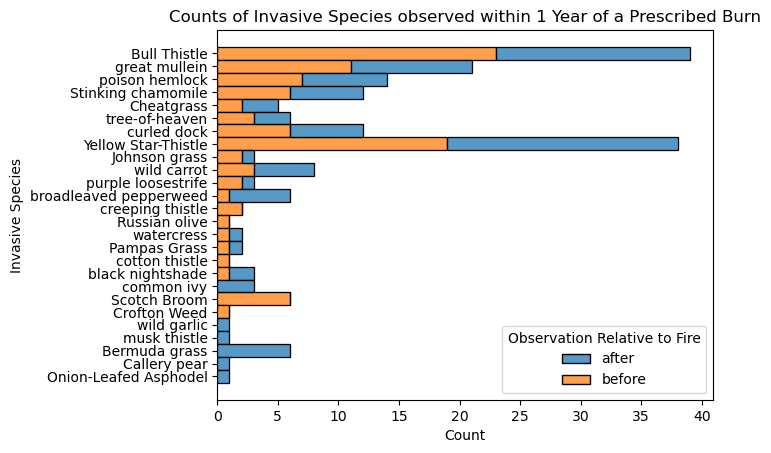

In [5]:
g = sns.histplot(data = invasives_within_year, y = "common_name", hue= "before_after", hue_order= ["after", "before"], multiple= "stack")

g.set(xlabel = "Count",
      ylabel = "Invasive Species",
      title = "Counts of Invasive Species observed within 1 Year of a Prescribed Burn"
              );
g.get_legend().set_title("Observation Relative to Fire")

Figure Overview:
This figure looks at the question: Are prescribed fires more effective in combating certain invasive species than others? We studied this question by visualizing the difference between invasive observation counts one year before and one year after a prescribed burn for each invasive species. We observe that bull thistle and yellow star-thistle, the two most prominent invasive species observed, have significantly increased in presence after prescribed burns. There were 40 bull thistle observed after prescribed burns across the state, and around 24 were observed before the presence of prescribed burns. There were around 38 yellow star-thistles observed after the occurrence of prescribed burns, with around 19 observed before the burns had occurred. For most species, there does seem to be an observed increase in species presence after prescribed burns. The species common ivy, wild garlic, musk thistle, bermuda grass, callery pear, and onion-leaf aspodel, had no presence before prescribed burns, but began emerging after prescribed burns had taken place. For species cotton thistle, scotch broom, and crofton weed, there are observations before prescribed fire, but none after. There are no units for species count and invasive species name. 

Limitations:
A major limitation of our plot is that the observations we have before a fire may not be in the same place with the observations we observe after fire. Therefore, this plot does not accurately show an increase or decrease in species presence. It could be possible that after prescribed fire, there was no longer the presence of the invasive species in certain regions, but would pop up a year after a burn in other regions independently. 

Findings:
We find that overall, prescribed fires are not effective in the removal of invasive plant species. Only for three species: cotton thistle, scotch broom, and crofton weed do we observe no presence of these species a year after prescribed burns occur.

In [6]:
invasives_table = invasives_within_year.loc[:, ["common_name", "before_after"]]

invasives_summary = invasives_table.groupby(["common_name", "before_after"]).size().reset_index(name="count")

In [7]:
invasives_summary_wide = (
    invasives_summary
    .pivot_table(
        index = "common_name",
        columns = "before_after",
        values = "count"
    )
    .fillna(0)
    .reset_index()
)

invasives_summary_wide = invasives_summary_wide[
    ["common_name", "before", "after"]
]

In [8]:
invasives_summary_wide_nice = (
    invasives_summary_wide
    .assign(
        Before = lambda df: df["before"].astype(int),
        After = lambda df: df["after"].astype(int)
    )
    .rename_axis(columns=None)
    .reset_index(drop=True)
)

In [9]:
invasives_summary_wide_nice.loc[:, ["common_name", "Before", "After"]]

,common_name,Before,After
0,Bermuda grass,0,6
1,Bull Thistle,23,16
2,Callery pear,0,1
3,Cheatgrass,2,3
4,Crofton Weed,1,0
5,Johnson grass,2,1
6,Onion-Leafed Asphodel,0,1
7,Pampas Grass,1,1
8,Russian olive,1,0
9,Scotch Broom,6,0


There is not a clear trend in invasive species presence in response to prescribed burns. Most species had similar numbers of observations before and after the burns. The takeaways here are similar to what is written above for the "Counts of Invasive Species observed within 1 Year of a Prescribed Burn" graph.

In [11]:
# View the first rows of the spatially joined table
fire_with_plants_joined.head()

,id,observation_date,location,scientific_name,common_name,index_right,year,agency,burn_name,treatment_type,start_date,end_date,acres_treated,gis_acres_treated,Shape_Length,Shape_Area,duration_days,before_after,geometry
0,13970,2011-04-03,"3625 Franz Valley Rd, Santa Rosa, CA 95404, USA",Rumex crispus,curled dock,52,2025,CDF,2025 Burning,1.0,2025-10-23,2025-10-23,65.300000,65.295486,2506.015104,2.642415e+05,0.0,neither,POINT (-233986.028 64967.46)
1,15877,2011-04-29,Pepperwood Preserve,Rumex crispus,curled dock,2592,2019,PVT,Pepperwood,1.0,2019-10-23,2019-10-23,2105.000000,2105.398193,28228.619203,8.520244e+06,0.0,neither,POINT (-234921.835 66445.989)
2,35540,2011-10-12,"13499 Cook Ln, Healdsburg, CA 95448, , United...",Cirsium vulgare,Bull Thistle,2592,2019,PVT,Pepperwood,1.0,2019-10-23,2019-10-23,2105.000000,2105.398193,28228.619203,8.520244e+06,0.0,neither,POINT (-236641.57 67748.834)
3,45440,2011-12-31,"37.89432907104492, -122.58660125732422",Cytisus scoparius,Scotch Broom,935,2024,CSP,Mount Tamalpais SP Rx,1.0,2024-10-10,2024-10-10,13.620886,13.620939,1121.249397,5.512199e+04,0.0,neither,POINT (-227132.06 -10467.853)
4,56552,2012-03-09,"Santa Rosa, Sonoma, California, United States ...",Onopordum illyricum,Illyrian thistle,2592,2019,PVT,Pepperwood,1.0,2019-10-23,2019-10-23,2105.000000,2105.398193,28228.619203,8.520244e+06,0.0,neither,POINT (-238528.603 69116.118)


Initial analytical application:
We are using spatial analysis to observe the presence of invasive species in prescribed burn areas before and after the occurrence of the prescribed fire. This fits our question, because we need to be observing our data spatially to most accurately identify where there is spatial overlap between an invasive species observation and a prescribed fire. Prescribed fires can be small, and categorizing it into a county or a larger region won’t be helpful in our analysis. Therefore spatial analysis with geospatial polygons and points will be most useful to us in our analysis. 

We spatially joined our invasive species data with our prescribed burns data to look at which invasive species data falls into our prescribed burn polygons. We then plotted all observations that were observed within a prescribed burn polygon. Our joined table named “fire_with_plants_joined” is a validity check that spatially there is invasive species presence within regions of prescribed burn treatment (1481 observations). This check allows us to move forward with our analysis, and we use it to sort out the presence of invasive species a year before and a year after prescribed burn occurrence, as well as group invasive species by count to analyze the effectiveness of prescribed fires on invasive species.
